# Projeto Big Data — Classificação da gravidade de acidentes (PRF 2023)

## Modelo: AdaBoost com balanceamento por RandomOverSampler

### Principais alterações
- O conjunto original é dividido em treino, validação e teste, sempre respeitando os grupos por `id`.
- O limiar de classificação para `Grave/Fatal` é escolhido na validação, sem consultar o conjunto de teste.
- O CSV é salvo no Google Drive na primeira utilização; nas próximas sessões, o notebook lê o arquivo diretamente do Drive.
- A leitura usa somente as colunas necessárias, reduzindo o uso de RAM.
- O One-Hot Encoding usa uma matriz esparsa (`OneHotEncoder`), evitando criar centenas de colunas densas.
- O `RandomOverSampler` continua sendo usado, mas somente depois da divisão e somente no conjunto de treinamento.
- A divisão usa `StratifiedGroupKFold`, mantendo todos os registros de um mesmo `id` no treino ou no teste, sem misturá-los.
- A avaliação inclui Balanced Accuracy, ROC-AUC e Average Precision, além das métricas tradicionais.

**Execute as células em ordem, de cima para baixo.** Se o Colab reiniciar o ambiente, execute novamente desde a primeira célula. O CSV continuará salvo no Drive.

## 1. Instalação e bibliotecas

O código tenta importar `RandomOverSampler`. Caso `imbalanced-learn` não esteja instalado no ambiente, ele instala a biblioteca. As importações ficam nesta célula para evitar o `NameError` mostrado no print.

In [1]:
# Instala imbalanced-learn somente se ainda não estiver disponível.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

from imblearn.over_sampling import RandomOverSampler

import gc
import inspect
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    precision_recall_curve,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)

RANDOM_STATE = 42
N_SPLITS = 4  # Primeiro, separa aproximadamente 25% para teste
N_ESTIMATORS = 100
LEARNING_RATE = 0.5
RECALL_MINIMO = 0.60  # Alvo mínimo de recall na validação para a classe Grave/Fatal

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Carregamento da base pelo Google Drive

Na primeira execução, o notebook solicitará o CSV e salvará uma cópia em `Meu Drive/Projeto_AdaBoost_PRF_2023/`. Nas próximas execuções, ele encontrará o arquivo nessa pasta e **não solicitará novo upload**.

A primeira transferência ainda precisa acontecer uma vez. Como alternativa, você pode colocar manualmente o CSV nessa pasta do Drive antes de executar esta célula.

In [2]:
from google.colab import drive, files

drive.mount('/content/drive')

PASTA_PROJETO = Path('/content/drive/MyDrive/Projeto_AdaBoost_PRF_2023')
PASTA_PROJETO.mkdir(parents=True, exist_ok=True)
ARQUIVO_CSV = PASTA_PROJETO / 'acidentes2023_todas_causas_tipos.csv'

# Mude para True somente quando quiser substituir a cópia que já está no Drive.
FORCAR_NOVO_UPLOAD = False

if (not ARQUIVO_CSV.exists()) or FORCAR_NOVO_UPLOAD:
    print("O CSV ainda não está salvo no Drive. Selecione o arquivo uma única vez.")
    enviados = files.upload()
    csvs = [nome for nome in enviados.keys() if nome.lower().endswith('.csv')]

    if len(csvs) == 0:
        raise FileNotFoundError("Nenhum arquivo CSV foi enviado.")
    if len(csvs) > 1:
        raise ValueError("Envie somente o CSV acidentes2023_todas_causas_tipos.csv.")

    shutil.copy2(csvs[0], ARQUIVO_CSV)
    del enviados
    gc.collect()
    print(f"Arquivo salvo no Google Drive: {ARQUIVO_CSV}")
else:
    print("CSV encontrado no Google Drive. Não será necessário fazer upload novamente.")

print(f"Caminho da base: {ARQUIVO_CSV}")

Mounted at /content/drive
CSV encontrado no Google Drive. Não será necessário fazer upload novamente.
Caminho da base: /content/drive/MyDrive/Projeto_AdaBoost_PRF_2023/acidentes2023_todas_causas_tipos.csv


## 3. Leitura seletiva e limpeza dos dados

A base original possui 37 colunas, mas o modelo usa apenas as variáveis abaixo e o identificador `id`, necessário para separar grupos. Ler somente essas colunas reduz o uso de memória.

A limpeza mantém a regra do notebook recebido: registros sem idade, atributos de entrada ou contagens de vítimas são removidos; depois, são mantidos registros com pelo menos uma contagem de vítima. A classe `Grave/Fatal` é definida quando `mortos > 0` ou `feridos_graves > 0`.

In [3]:
# Colunas realmente utilizadas no projeto.
colunas_texto = [
    "dia_semana",
    "tipo_veiculo",
    "tipo_pista",
    "condicao_meteorologica",
    "fase_dia",
    "causa_acidente",
    "tipo_acidente",
    "tracado_via",
    "uso_solo",
    "tipo_envolvido",
    "sexo",
]

colunas_vitimas = ["ilesos", "feridos_leves", "feridos_graves", "mortos"]
colunas_analise = ["idade"] + colunas_texto

# No CSV original, a coluna está grafada como 'condicao_metereologica'.
colunas_csv = [
    "id", "idade", "dia_semana", "tipo_veiculo", "tipo_pista",
    "condicao_metereologica", "fase_dia", "causa_acidente",
    "tipo_acidente", "tracado_via", "uso_solo", "tipo_envolvido",
    "sexo", "ilesos", "feridos_leves", "feridos_graves", "mortos"
]

df = pd.read_csv(
    ARQUIVO_CSV,
    sep=";",
    encoding="latin1",
    usecols=colunas_csv,
    low_memory=False
)

df.columns = df.columns.str.strip()
df = df.rename(columns={"condicao_metereologica": "condicao_meteorologica"})
linhas_iniciais = len(df)

# Padronização dos campos categóricos.
for col in colunas_texto:
    df[col] = df[col].astype("string").str.strip().str.lower()

# Padronização do campo de uso do solo, seguindo a regra do notebook original.
df["uso_solo"] = df["uso_solo"].replace({
    "sim": "urbano",
    "não": "rural",
    "nao": "rural"
})

valores_invalidos = [
    "", " ", "nan", "null", "none", "(null)",
    "ignorado", "não informado", "nao informado",
    "sem informação", "sem informacao"
]
for col in colunas_texto:
    df[col] = df[col].replace(valores_invalidos, pd.NA)

# Conversões numéricas.
df["idade"] = pd.to_numeric(df["idade"], errors="coerce")
df.loc[(df["idade"] < 0) | (df["idade"] > 120), "idade"] = np.nan

for col in colunas_vitimas:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Preserva a regra de limpeza do notebook recebido.
df_limpo = df.dropna(subset=colunas_analise + colunas_vitimas).copy()
del df
gc.collect()

df_limpo["idade"] = df_limpo["idade"].astype("int16")
for col in colunas_vitimas:
    df_limpo[col] = df_limpo[col].astype("int32")

df_limpo["faixa_etaria"] = pd.cut(
    df_limpo["idade"],
    bins=[-1, 17, 29, 39, 49, 59, 120],
    labels=[
        "0 a 17 anos", "18 a 29 anos", "30 a 39 anos",
        "40 a 49 anos", "50 a 59 anos", "60+ anos"
    ]
)

# Manter somente registros com pelo menos uma vítima contabilizada.
mascara_com_vitima = (df_limpo[colunas_vitimas] > 0).any(axis=1)
df_limpo = df_limpo.loc[mascara_com_vitima].copy()

# Variável-alvo binária.
df_limpo["gravidade_binaria"] = np.where(
    (df_limpo["mortos"] > 0) | (df_limpo["feridos_graves"] > 0),
    "Grave/Fatal",
    "Leve/Ileso"
)

print(f"Registros lidos: {linhas_iniciais:,}".replace(",", "."))
print(f"Registros após limpeza: {len(df_limpo):,}".replace(",", "."))
print(f"Registros removidos: {linhas_iniciais - len(df_limpo):,}".replace(",", "."))
print("\nDistribuição da variável-alvo:")
print(df_limpo["gravidade_binaria"].value_counts())
print("\nPercentual por classe:")
print((df_limpo["gravidade_binaria"].value_counts(normalize=True) * 100).round(2))

Registros lidos: 571.052
Registros após limpeza: 454.348
Registros removidos: 116.704

Distribuição da variável-alvo:
gravidade_binaria
Leve/Ileso     371083
Grave/Fatal     83265
Name: count, dtype: int64

Percentual por classe:
gravidade_binaria
Leve/Ileso     81.67
Grave/Fatal    18.33
Name: proportion, dtype: float64


## 4. Preparação das variáveis

O notebook original cria uma faixa etária e mantém a idade numérica, além das variáveis categóricas. Mantive essa escolha.

**Importante:** a unidade mantida aqui continua sendo cada linha válida da base. O identificador `id` será utilizado apenas para impedir que linhas da mesma ocorrência apareçam simultaneamente no treino e no teste; ele não será fornecido como atributo ao AdaBoost.

In [4]:
colunas_categoricas = ["faixa_etaria"] + colunas_texto
colunas_numericas = ["idade"]
colunas_para_ml = colunas_categoricas + colunas_numericas

X = df_limpo[colunas_para_ml].copy()
y = df_limpo["gravidade_binaria"].copy()
grupos = df_limpo["id"].copy()

# Categorias reduzem o consumo de memória no DataFrame antes da codificação.
for col in colunas_categoricas:
    X[col] = X[col].astype("category")
X["idade"] = X["idade"].astype("float32")

# Diagnóstico: alguns IDs podem conter linhas pertencentes às duas classes.
classes_por_id = df_limpo.groupby("id", observed=True)["gravidade_binaria"].nunique()
ids_com_duas_classes = int((classes_por_id > 1).sum())

print(f"Registros disponíveis para ML: {len(X):,}".replace(",", "."))
print(f"Atributos antes do One-Hot Encoding: {X.shape[1]}")
print(f"IDs distintos: {grupos.nunique():,}".replace(",", "."))
print(f"IDs associados às duas classes: {ids_com_duas_classes:,}".replace(",", "."))

# Libera a cópia de limpeza; X, y e grupos já guardam o que será usado.
del df_limpo, classes_por_id
gc.collect()

Registros disponíveis para ML: 454.348
Atributos antes do One-Hot Encoding: 13
IDs distintos: 63.910
IDs associados às duas classes: 11.486


0

## 5. Divisão entre treino, validação e teste, respeitando os grupos

O conjunto é dividido em três partes usando `StratifiedGroupKFold`:
- aproximadamente 60% para treinamento;
- aproximadamente 15% para validação;
- aproximadamente 25% para teste final.

Todos os registros com o mesmo `id` permanecem em apenas uma dessas partes. A validação será usada para escolher o limiar de classificação; o teste fica reservado para a avaliação final.


In [5]:
# 1) Reserva aproximadamente 25% dos grupos para o teste final.
divisor_teste = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

idx_treino_val, idx_teste = next(divisor_teste.split(X, y, groups=grupos))

# 2) Separa aproximadamente 20% do bloco treino+validação para validação.
# Evitamos copiar o bloco inteiro; usamos os índices relativos para voltar à base original.
X_treino_val = X.iloc[idx_treino_val]
y_treino_val = y.iloc[idx_treino_val]
grupos_treino_val = grupos.iloc[idx_treino_val]

divisor_validacao = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 1
)

idx_treino_rel, idx_val_rel = next(
    divisor_validacao.split(
        X_treino_val,
        y_treino_val,
        groups=grupos_treino_val
    )
)

idx_treino = idx_treino_val[idx_treino_rel]
idx_validacao = idx_treino_val[idx_val_rel]

X_train = X.iloc[idx_treino].copy()
y_train = y.iloc[idx_treino].copy()
X_val = X.iloc[idx_validacao].copy()
y_val = y.iloc[idx_validacao].copy()
X_test = X.iloc[idx_teste].copy()
y_test = y.iloc[idx_teste].copy()

# Confirma que nenhum id aparece em mais de uma parte.
ids_treino = set(grupos.iloc[idx_treino].unique())
ids_validacao = set(grupos.iloc[idx_validacao].unique())
ids_teste = set(grupos.iloc[idx_teste].unique())

assert ids_treino.isdisjoint(ids_validacao), "ERRO: há IDs compartilhados entre treino e validação."
assert ids_treino.isdisjoint(ids_teste), "ERRO: há IDs compartilhados entre treino e teste."
assert ids_validacao.isdisjoint(ids_teste), "ERRO: há IDs compartilhados entre validação e teste."

print(f"Total no treino: {len(X_train):,}".replace(",", "."))
print(f"Total na validação: {len(X_val):,}".replace(",", "."))
print(f"Total no teste: {len(X_test):,}".replace(",", "."))
print(f"IDs no treino: {len(ids_treino):,}".replace(",", "."))
print(f"IDs na validação: {len(ids_validacao):,}".replace(",", "."))
print(f"IDs no teste: {len(ids_teste):,}".replace(",", "."))

print("\nClasses no treino antes do balanceamento:")
print(y_train.value_counts())
print("\nClasses na validação (sem balanceamento):")
print(y_val.value_counts())
print("\nClasses no teste (sem balanceamento):")
print(y_test.value_counts())

# Libera os objetos temporários e índices.
del X, y, grupos, X_treino_val, y_treino_val, grupos_treino_val
del ids_treino, ids_validacao, ids_teste
gc.collect()


Total no treino: 271.239
Total na validação: 71.144
Total no teste: 111.965
IDs no treino: 38.342
IDs na validação: 9.606
IDs no teste: 15.962

Classes no treino antes do balanceamento:
gravidade_binaria
Leve/Ileso     221849
Grave/Fatal     49390
Name: count, dtype: int64

Classes na validação (sem balanceamento):
gravidade_binaria
Leve/Ileso     58307
Grave/Fatal    12837
Name: count, dtype: int64

Classes no teste (sem balanceamento):
gravidade_binaria
Leve/Ileso     90927
Grave/Fatal    21038
Name: count, dtype: int64


0

## 6. One-Hot Encoding com matriz esparsa

O `pd.get_dummies()` pode criar uma matriz densa muito grande. Aqui, `OneHotEncoder` cria uma matriz esparsa, armazenando principalmente os valores diferentes de zero.

O pré-processador é ajustado exclusivamente no treino e aplicado sem novo ajuste na validação e no teste, evitando vazamento de informação.


In [6]:
# Compatibilidade com versões antigas e novas do scikit-learn.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
        dtype=np.float32
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True,
        dtype=np.float32
    )

preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", encoder, colunas_categoricas),
        ("numericas", "passthrough", colunas_numericas)
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# Ajusta somente no treino; validação e teste apenas recebem a transformação.
X_train_enc = preprocessador.fit_transform(X_train)
X_val_enc = preprocessador.transform(X_val)
X_test_enc = preprocessador.transform(X_test)

X_train_enc = sparse.csr_matrix(X_train_enc, dtype=np.float32)
X_val_enc = sparse.csr_matrix(X_val_enc, dtype=np.float32)
X_test_enc = sparse.csr_matrix(X_test_enc, dtype=np.float32)

def memoria_matriz_mb(matriz):
    if sparse.issparse(matriz):
        total_bytes = matriz.data.nbytes + matriz.indices.nbytes + matriz.indptr.nbytes
    else:
        total_bytes = matriz.nbytes
    return total_bytes / (1024 ** 2)

print("Formato do treino:", type(X_train_enc).__name__)
print("Dimensão do treino:", X_train_enc.shape)
print("Dimensão da validação:", X_val_enc.shape)
print("Dimensão do teste:", X_test_enc.shape)
print(f"Memória da matriz de treino: {memoria_matriz_mb(X_train_enc):.2f} MB")
print(f"Memória da matriz de validação: {memoria_matriz_mb(X_val_enc):.2f} MB")
print(f"Memória da matriz de teste: {memoria_matriz_mb(X_test_enc):.2f} MB")

# Libera os DataFrames já transformados.
del X_train, X_val, X_test, preprocessador
gc.collect()


Formato do treino: csr_matrix
Dimensão do treino: (271239, 602)
Dimensão da validação: (71144, 602)
Dimensão do teste: (111965, 602)
Memória da matriz de treino: 27.93 MB
Memória da matriz de validação: 7.33 MB
Memória da matriz de teste: 11.53 MB


69

## 7. Balanceamento do conjunto de treinamento

O `RandomOverSampler` replica exemplos da classe minoritária até igualar as quantidades. Ele é aplicado **somente ao treino**. A validação e o teste permanecem com a distribuição original.

A matriz é esparsa para reduzir o uso de memória. Mantemos também a matriz de treino original para permitir, opcionalmente, comparar o oversampling com pesos de classe em outra execução.


In [7]:
balanceador = RandomOverSampler(random_state=RANDOM_STATE)

X_train_bal, y_train_bal = balanceador.fit_resample(
    X_train_enc,
    y_train
)

contagem_antes = y_train.value_counts()
contagem_depois = y_train_bal.value_counts()

print("Distribuição antes do balanceamento:")
print(contagem_antes)
print("\nDistribuição após o balanceamento:")
print(contagem_depois)

print("\nTamanho do treino antes:", len(y_train))
print("Tamanho do treino depois:", len(y_train_bal))
print("Tamanho da validação (inalterado):", len(y_val))
print("Tamanho do teste (inalterado):", len(y_test))
print(f"Memória da matriz balanceada: {memoria_matriz_mb(X_train_bal):.2f} MB")

assert contagem_depois.nunique() == 1, "As classes não ficaram com a mesma quantidade."
assert len(y_val) == X_val_enc.shape[0], "A validação foi alterada inesperadamente."
assert len(y_test) == X_test_enc.shape[0], "O conjunto de teste foi alterado inesperadamente."
print("\nVerificação concluída: treino balanceado; validação e teste preservados.")

del balanceador, contagem_antes, contagem_depois
gc.collect()


Distribuição antes do balanceamento:
gravidade_binaria
Leve/Ileso     221849
Grave/Fatal     49390
Name: count, dtype: int64

Distribuição após o balanceamento:
gravidade_binaria
Leve/Ileso     221849
Grave/Fatal    221849
Name: count, dtype: int64

Tamanho do treino antes: 271239
Tamanho do treino depois: 443698
Tamanho da validação (inalterado): 71144
Tamanho do teste (inalterado): 111965
Memória da matriz balanceada: 45.70 MB

Verificação concluída: treino balanceado; validação e teste preservados.


0

## 8. Treinamento do AdaBoost

A configuração principal do parceiro foi mantida:
- `DecisionTreeClassifier(max_depth=1)` como estimador-base;
- `n_estimators=100`;
- `learning_rate=0.5`;
- `random_state=42`.

A construção do parâmetro do estimador-base é compatível com versões do scikit-learn que usam `estimator` ou `base_estimator`.

In [8]:
estimador_base = DecisionTreeClassifier(
    max_depth=1,
    random_state=RANDOM_STATE
)

parametros_ada = {
    "n_estimators": N_ESTIMATORS,
    "learning_rate": LEARNING_RATE,
    "random_state": RANDOM_STATE
}

# Compatibilidade: versões recentes usam 'estimator'; versões antigas, 'base_estimator'.
parametros_aceitos = inspect.signature(AdaBoostClassifier).parameters
if "estimator" in parametros_aceitos:
    parametros_ada["estimator"] = estimador_base
else:
    parametros_ada["base_estimator"] = estimador_base

adaboost = AdaBoostClassifier(**parametros_ada)

print("Iniciando treinamento do AdaBoost...", flush=True)
adaboost.fit(X_train_bal, y_train_bal)
print("Treinamento do AdaBoost concluído.")

# Libera a matriz balanceada, que é grande e não será necessária na avaliação.
del X_train_bal, y_train_bal
gc.collect()

Iniciando treinamento do AdaBoost...
Treinamento do AdaBoost concluído.


0

## 9. Escolha do limiar na validação e avaliação final no teste

O AdaBoost fornece probabilidades. O limiar padrão pode gerar muitos falsos positivos para a classe `Grave/Fatal`. Aqui escolhemos um limiar usando somente a validação, buscando a maior precisão possível enquanto o recall da classe grave permanece acima de `RECALL_MINIMO`.

O conjunto de teste não participa dessa escolha. Ele será usado apenas para medir o resultado final.


Critério: Maior precisão com recall >= 60%
Limiar escolhido na validação: 0.5075
Precisão na validação nesse limiar: 0.3054
Recall na validação nesse limiar: 0.6102
F1-score na validação nesse limiar: 0.4071

Métricas de ranking no teste (não dependem do limiar):
ROC-AUC: 0.7259
Average Precision: 0.4015

=== TESTE COM LIMIAR PADRÃO DO ADA BOOST ===
Accuracy: 0.6650
Balanced Accuracy: 0.6570
              precision    recall  f1-score   support

  Leve/Ileso     0.8906    0.6698    0.7646     90927
 Grave/Fatal     0.3110    0.6443    0.4195     21038

    accuracy                         0.6650    111965
   macro avg     0.6008    0.6570    0.5920    111965
weighted avg     0.7817    0.6650    0.6997    111965


=== TESTE COM LIMIAR ESCOLHIDO NA VALIDAÇÃO ===
Accuracy: 0.6756
Balanced Accuracy: 0.6559
              precision    recall  f1-score   support

  Leve/Ileso     0.8877    0.6874    0.7748     90927
 Grave/Fatal     0.3160    0.6243    0.4197     21038

    accuracy          

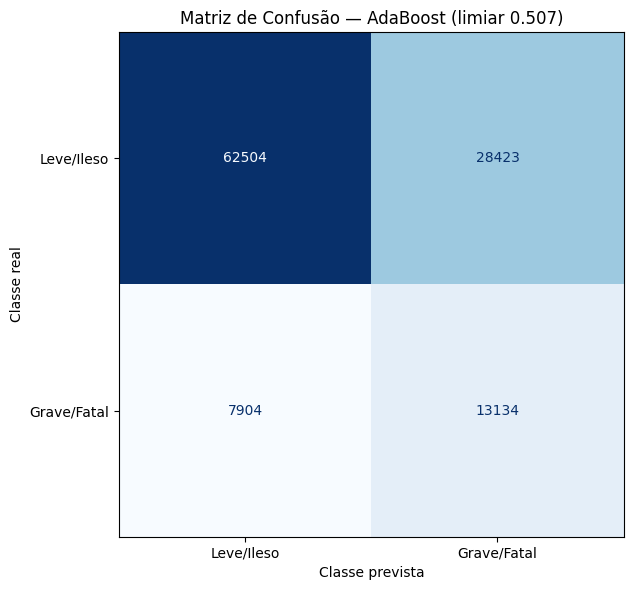

In [9]:
# Probabilidade estimada para Grave/Fatal na validação.
indice_grave = list(adaboost.classes_).index("Grave/Fatal")
y_val_binario = (y_val == "Grave/Fatal").astype(int)
y_prob_val = adaboost.predict_proba(X_val_enc)[:, indice_grave]

prec_val, rec_val, limiares_val = precision_recall_curve(y_val_binario, y_prob_val)

# A precisão/recall têm um elemento a mais que o vetor de limiares.
prec_com_limiar = prec_val[:-1]
rec_com_limiar = rec_val[:-1]
f1_com_limiar = (
    2 * prec_com_limiar * rec_com_limiar /
    np.maximum(prec_com_limiar + rec_com_limiar, 1e-12)
)

candidatos = np.flatnonzero(rec_com_limiar >= RECALL_MINIMO)
if len(candidatos) > 0:
    # Entre os limiares que respeitam o recall mínimo, escolhe o de maior precisão.
    melhor_idx = candidatos[np.argmax(prec_com_limiar[candidatos])]
    criterio_limiar = f"Maior precisão com recall >= {RECALL_MINIMO:.0%}"
else:
    # Se o alvo de recall não for alcançável, usa o limiar de maior F1 na validação.
    melhor_idx = int(np.argmax(f1_com_limiar))
    criterio_limiar = "Recall mínimo não alcançado; usado o maior F1-score da validação"

limiar_escolhido = float(limiares_val[melhor_idx])
print("Critério:", criterio_limiar)
print(f"Limiar escolhido na validação: {limiar_escolhido:.4f}")
print(f"Precisão na validação nesse limiar: {prec_com_limiar[melhor_idx]:.4f}")
print(f"Recall na validação nesse limiar: {rec_com_limiar[melhor_idx]:.4f}")
print(f"F1-score na validação nesse limiar: {f1_com_limiar[melhor_idx]:.4f}")

# A partir daqui, o teste é usado somente para avaliação final.
y_test_binario = (y_test == "Grave/Fatal").astype(int)
y_prob_grave = adaboost.predict_proba(X_test_enc)[:, indice_grave]
y_pred_padrao = adaboost.predict(X_test_enc)
y_pred = np.where(y_prob_grave >= limiar_escolhido, "Grave/Fatal", "Leve/Ileso")

print("\nMétricas de ranking no teste (não dependem do limiar):")
print(f"ROC-AUC: {roc_auc_score(y_test_binario, y_prob_grave):.4f}")
print(f"Average Precision: {average_precision_score(y_test_binario, y_prob_grave):.4f}")

print("\n=== TESTE COM LIMIAR PADRÃO DO ADA BOOST ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_padrao):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_padrao):.4f}")
print(classification_report(
    y_test,
    y_pred_padrao,
    labels=["Leve/Ileso", "Grave/Fatal"],
    digits=4,
    zero_division=0
))

print("\n=== TESTE COM LIMIAR ESCOLHIDO NA VALIDAÇÃO ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(classification_report(
    y_test,
    y_pred,
    labels=["Leve/Ileso", "Grave/Fatal"],
    digits=4,
    zero_division=0
))

ordem_classes = ["Leve/Ileso", "Grave/Fatal"]
cm = confusion_matrix(y_test, y_pred, labels=ordem_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ordem_classes)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title(f"Matriz de Confusão — AdaBoost (limiar {limiar_escolhido:.3f})")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()


## 10. Curvas ROC e Precision-Recall

As curvas são calculadas a partir das probabilidades do teste original. Elas avaliam a capacidade de ranqueamento do modelo ao longo de diferentes limiares; não dependem do limiar escolhido para a matriz de confusão.


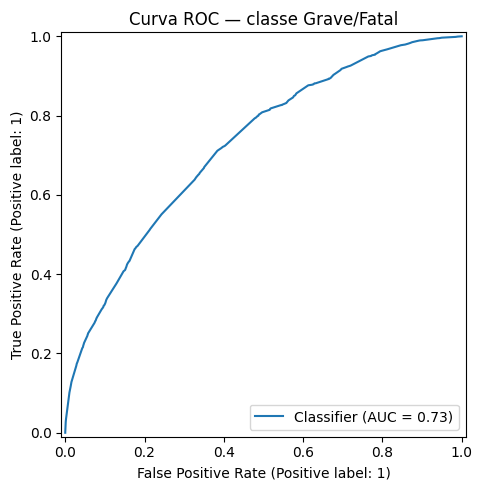

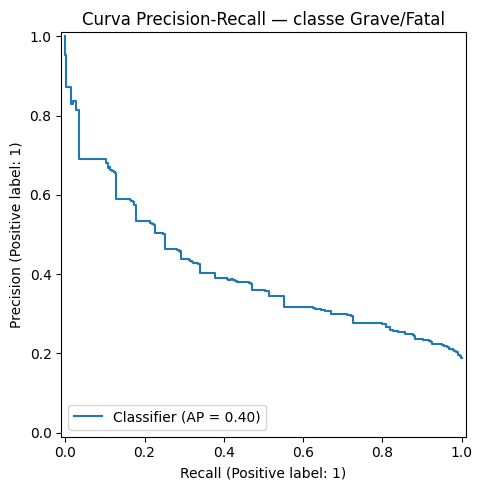

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test_binario, y_prob_grave, ax=ax)
ax.set_title("Curva ROC — classe Grave/Fatal")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test_binario, y_prob_grave, ax=ax)
ax.set_title("Curva Precision-Recall — classe Grave/Fatal")
plt.tight_layout()
plt.show()

## 11. Resumo visual das métricas por classe

,Precisão,Recall,F1-score,Suporte
Classe,,,,
Leve/Ileso,0.888,0.687,0.775,"90,927"
Grave/Fatal,0.316,0.624,0.420,"21,038"


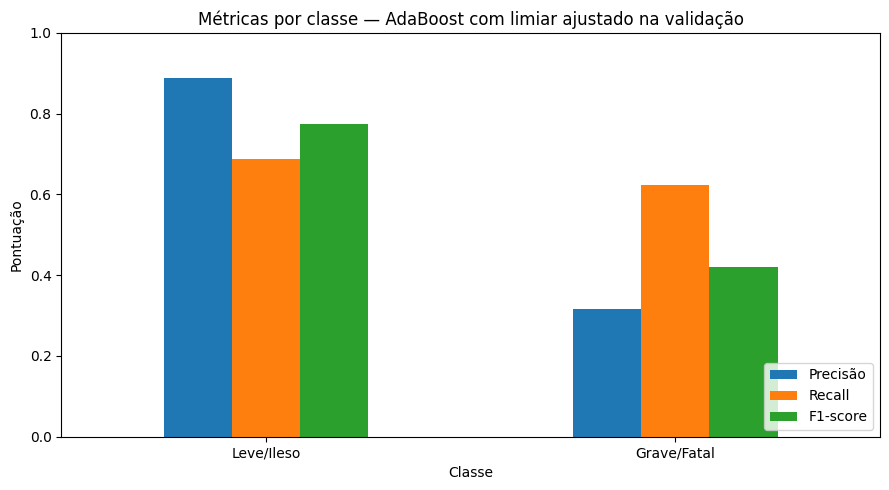

In [11]:
precisao, recall, f1, suporte = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=ordem_classes,
    zero_division=0
)

metricas = pd.DataFrame({
    "Classe": ordem_classes,
    "Precisão": precisao,
    "Recall": recall,
    "F1-score": f1,
    "Suporte": suporte
}).set_index("Classe")

display(metricas.style.format({
    "Precisão": "{:.3f}",
    "Recall": "{:.3f}",
    "F1-score": "{:.3f}",
    "Suporte": "{:,.0f}"
}))

ax = metricas[["Precisão", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
ax.set_title("Métricas por classe — AdaBoost com limiar ajustado na validação")
ax.set_ylabel("Pontuação")
ax.set_xlabel("Classe")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Interpretação e limitações

- O **Recall de Grave/Fatal** indica a proporção de registros graves/fatais reais identificados pelo modelo.
- A **Precisão de Grave/Fatal** indica quantas previsões dessa classe estavam corretas.
- A **Acurácia** pode ser enganosa quando as classes têm proporções diferentes.
- O **RandomOverSampler** replica linhas da classe minoritária; ele não cria novos exemplos independentes. Isso pode aumentar o risco de sobreajuste.
- A validação serve para escolher o limiar; o teste permanece intocado até a avaliação final.
- Mudar o limiar altera o equilíbrio entre precisão e recall, mas **não melhora por si só a ROC-AUC ou a Average Precision**. Para melhorar a capacidade de separação, é necessário experimentar atributos, modelos e hiperparâmetros.

